In [ ]:
%pip install matplotlib seaborn numpy pandas torch datasets transformers

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import time
import copy
import gc

import matplotlib.pyplot as plt
import seaborn as sns
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn

from utils import get_opt, get_loaders, eval_ppl

In [3]:
DEV = torch.device('cuda:0') if torch.cuda.is_available() else torch.device('cpu')

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

# Load

## Model

In [6]:
# model_name = "HuggingFaceTB/SmolLM2-135M"
model_name = "HuggingFaceTB/SmolLM2-1.7B"

model = get_opt(model_name)
model.eval()
model.to(DEV)

LlamaForCausalLM(
  (model): LlamaModel(
    (embed_tokens): Embedding(49152, 2048)
    (layers): ModuleList(
      (0-23): 24 x LlamaDecoderLayer(
        (self_attn): LlamaAttention(
          (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (k_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (v_proj): Linear(in_features=2048, out_features=2048, bias=False)
          (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
        )
        (mlp): LlamaMLP(
          (gate_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (up_proj): Linear(in_features=2048, out_features=8192, bias=False)
          (down_proj): Linear(in_features=8192, out_features=2048, bias=False)
          (act_fn): SiLU()
        )
        (input_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
        (post_attention_layernorm): LlamaRMSNorm((2048,), eps=1e-05)
      )
    )
    (norm): LlamaRMSNorm((2048,), eps=1e-05)
    (rotary_emb)

## Datasets

In [6]:
n_samples = 32

dataloader, testloader = get_loaders(
    "c4", nsamples=n_samples, seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (8597 > 8192). Running this sequence through the model will result in indexing errors


In [7]:
wiki_dataloader, wiki_testloader = get_loaders(
    'wikitext2', seed=0, model=model_name, seqlen=model.seqlen
)

Token indices sequence length is longer than the specified maximum sequence length for this model (2565857 > 8192). Running this sequence through the model will result in indexing errors


ts torch.Size([1, 2565857])



---
# Compute MLP output norm


In [8]:
def block_influence(input_hidden_state, output_hidden_state):
    d = input_hidden_state.shape[-1]
    input_hidden_state = input_hidden_state.reshape(-1, d)
    output_hidden_state = output_hidden_state.reshape(-1, d)

    norm_input = input_hidden_state.norm(dim=-1, keepdim=True)
    norm_output = output_hidden_state.norm(dim=-1, keepdim=True)

    sim = (input_hidden_state @ output_hidden_state.T) / (norm_input * norm_output)
    sim = sim.diagonal().nan_to_num(nan=0.5)

    return 1 - sim


def compute_bi(hiddens, importance):
    # compute block influence based on hidden states from one batch for each block
    n = 1
    for i in range(len(hiddens) - n):
        in_hidden = hiddens[i]
        out_hidden = hiddens[i+n]
        importance[i] += block_influence(
            in_hidden,
            out_hidden
        ).sum().cpu().item()

In [9]:
@torch.no_grad()
def shortGPT_importance(model):
    def hook_save_hidden_states(module, inps, outs):
        hiddens.append(outs[0].cpu())

    use_cache = model.config.use_cache
    model.config.use_cache = False
    
    importance = [0 for _ in model.model.layers]
    
    h = model.model.embed_tokens.register_forward_hook(hook_save_hidden_states)
    hooks = [h]
    for layer in model.model.layers:
        h = layer.register_forward_hook(hook_save_hidden_states)
        hooks.append(h)
    try:
        for batch in dataloader:
            hiddens = []
            model(batch[0].to(DEV))
            compute_bi(hiddens, importance)
            torch.cuda.empty_cache()
    finally:
        model.config.use_cache = use_cache
        for h in hooks:
            h.remove()
    return importance

importance = shortGPT_importance(model)

In [10]:
importance

[229280.0,
 67320.0,
 28600.0,
 25704.0,
 19868.0,
 17704.0,
 16238.0,
 17190.0,
 18840.0,
 21380.0,
 21060.0,
 17980.0,
 17514.0,
 14342.0,
 16204.0,
 17606.0,
 18824.0,
 18650.0,
 19432.0,
 17838.0,
 12966.0,
 11410.0,
 12968.0,
 128288.0]

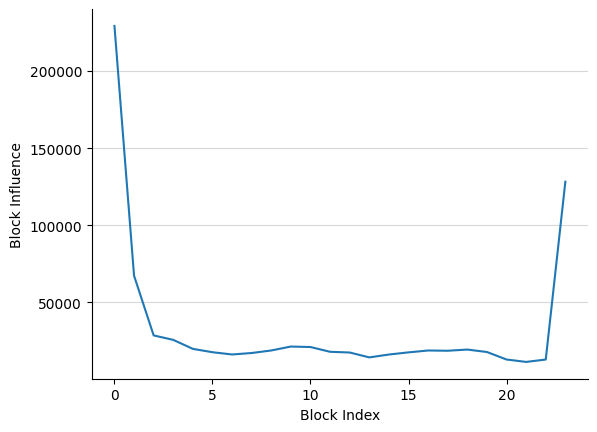

In [11]:
plt.plot(importance)
plt.xlabel('Block Index')
plt.ylabel('Block Influence')
plt.grid(axis='y', alpha=0.5)
sns.despine()

In [13]:
imp_df = pd.DataFrame(importance, columns=["BI"])
imp_df.to_csv('shortGPT_bi.csv')

In [12]:
imp_df = pd.read_csv('shortGPT_bi.csv', index_col=0)
importance = imp_df['BI'].to_list()

---
# Layer-Skipping Strategies

In [11]:
class SkipMLP(nn.Module):
    def forward(self, x):
        return torch.zeros_like(x, device=DEV)

In [17]:
# n_prune_layers = 10
# layers_to_remove = np.argsort(np.array(importance))[:self.n_prune_layers].tolist()
layers_to_remove = np.argsort(np.array(importance)).tolist()

## Removing layers from the least significant

In [20]:
results_shortGPT = pd.DataFrame(columns=["perplexity"])

num_skipped = 0

ppl = eval_ppl(model, wiki_testloader, device=DEV)
results_shortGPT.loc[num_skipped] = [ppl]
print(f'ppl {ppl}\n')

for n_prune_layers in range(1, len(model.model.layers)+1):
    # reload model to recover all layers and avoid indexing problems
    model = get_opt(model_name)
    model.eval()
    model.to(DEV)
    
    layers_to_remove = np.argsort(np.array(importance))[:n_prune_layers].tolist()
    print('removing:', layers_to_remove)

    for layer_idx in sorted(layers_to_remove, reverse=True):
        del model.model.layers[layer_idx]

    gc.collect()
    torch.cuda.empty_cache()
    num_skipped += 1
    
    ppl = eval_ppl(model, wiki_testloader, device=DEV)
    results_shortGPT.loc[num_skipped] = [ppl]
    print(f'ppl {ppl}\n')

    if ppl > 1e4: break

results_shortGPT.to_csv('results_shortGPT.csv')
results_shortGPT

ppl 7.260688781738281

removing: [21]
ppl 9.52587604522705

removing: [21, 20]
ppl 13.385505676269531

removing: [21, 20, 22]
ppl 27.050886154174805

removing: [21, 20, 22, 13]
ppl 28.746915817260742

removing: [21, 20, 22, 13, 14]
ppl 35.58024978637695

removing: [21, 20, 22, 13, 14, 6]
ppl 184.85928344726562

removing: [21, 20, 22, 13, 14, 6, 7]
ppl 3067.80029296875

removing: [21, 20, 22, 13, 14, 6, 7, 12]
ppl 5262.77001953125

removing: [21, 20, 22, 13, 14, 6, 7, 12, 15]
ppl 3514.652099609375

removing: [21, 20, 22, 13, 14, 6, 7, 12, 15, 5]
ppl 10762.078125



,perplexity
0,7.260689
1,9.525876
2,13.385506
3,27.050886
4,28.746916
5,35.580250
6,184.859283
7,3067.800293
8,5262.770020
9,3514.652100


## Results

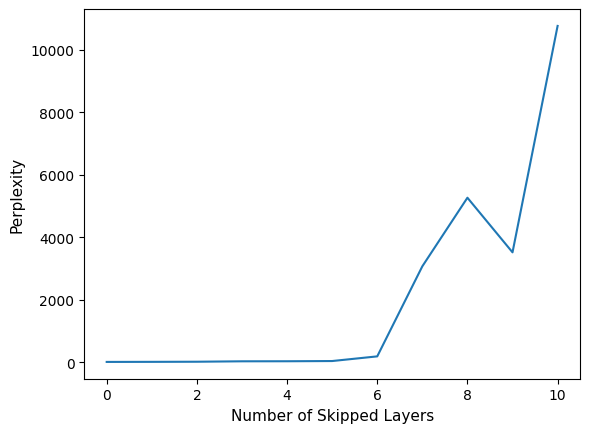

In [26]:
plt.plot(results_shortGPT.perplexity)
plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Perplexity', fontsize=11);

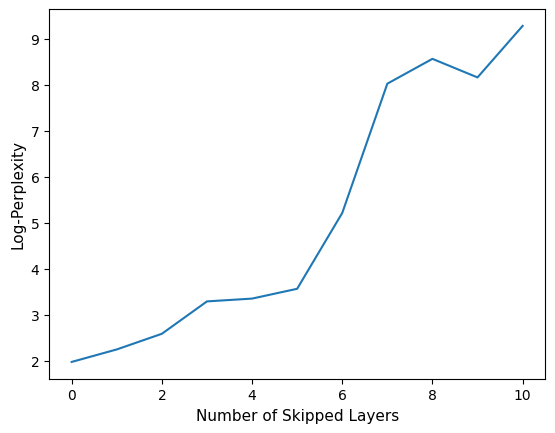

In [25]:
results_shortGPT['log_perplexity'] = np.log(results_shortGPT.perplexity)
plt.plot(results_shortGPT.log_perplexity)
plt.xlabel('Number of Skipped Layers', fontsize=11)
plt.ylabel('Log-Perplexity', fontsize=11);